# Full temporal MAE rollout within clips

One TinyMAE trajectory after the original 8,000-arrival calibration.
The run processes **71,936 arrivals in 750 clips**.
The first 1,152 arrivals fit the predictors and feature scales.
The remaining 70,784 arrivals form the chronological evaluation stream.

| Regime | Clips | Arrivals |
|---|---:|---:|
| daytime / clear | 375 | 36,000 |
| night / clear | 375 | 35,936 |

This adapts the time-of-day/weather ordering of the Phase 1.2 regime walk to the available
temporal BDD100K clips. The cache has clear daytime and clear night footage. Each clip retains
its original frame order. Regime metadata is used only to build the stream.

At origin $t$, the predictors estimate post-action reconstruction MSE, RankMe, feature
variance and LiDAR at $t+h$ on the pilot's fixed unlabeled monitor bank. Each uses the
currently observed health, 88 rich features and the predeclared skip/0.25×/1× LR sequence.
The open-loop forecast holds the rich features fixed and recursively feeds back predicted
health. Frozen and online variants start from the same fit. Online variants issue the forecast
before updating from the next observed health. Persistence repeats the issue-time health.

Each horizon uses all evaluation origins whose future training frames stay within the same
clip. All five predictors share those origins. A forecast may end immediately after the last
frame in its clip. The longest tested horizon is +64 because cached clips contain at most 96
frames. MAE state and predictor learning carry across clips.


## Pooled RMSE for persistence and online MLP

Each point pools the eligible forecasts at that horizon. Lower RMSE is better.

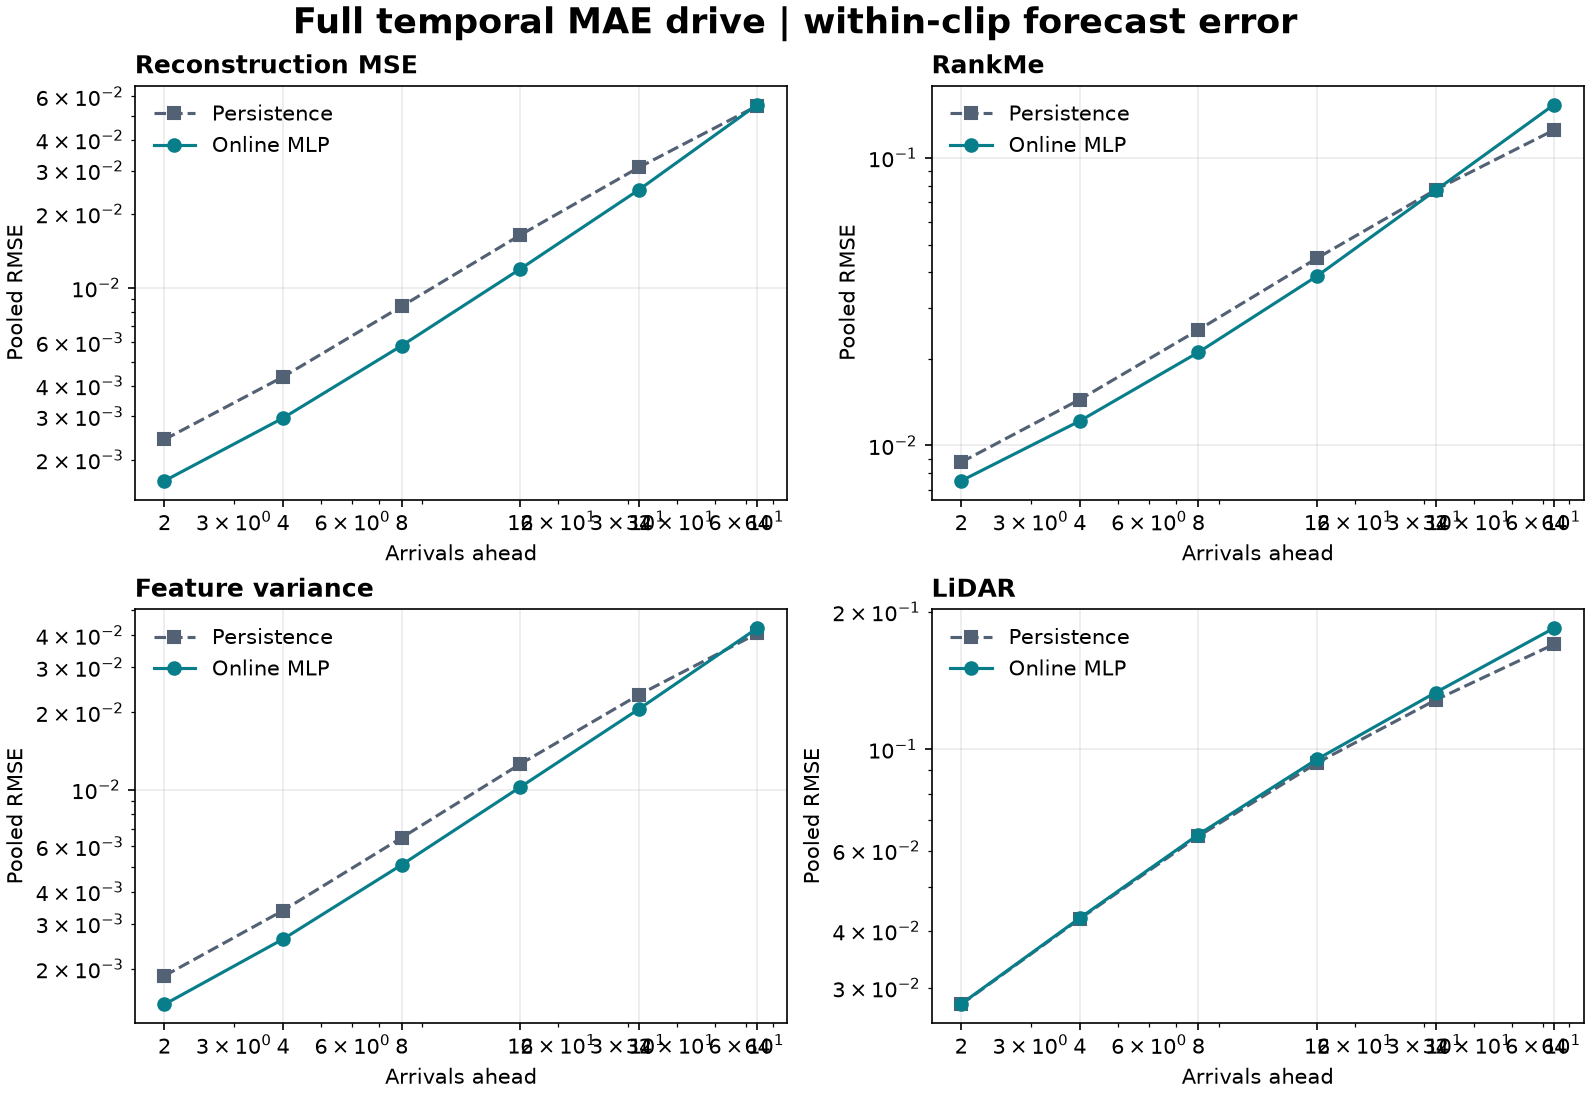

In [ ]:
from IPython.display import Image, display
display(Image(filename='rmse_persistence_vs_online_mlp.png'))


## Reconstruction MSE

| Horizon | Forecasts | Persistence | Lasso frozen | Lasso online | MLP frozen | MLP online |
|---:|---:|---:|---:|---:|---:|---:|
| +2 | 70,046 | 0.00241757 | 0.00185036 | 0.00158594 | 0.00404083 | 0.00164144 |
| +4 | 68,570 | 0.00434591 | 0.00316451 | 0.00264978 | 0.0073923 | 0.00295555 |
| +8 | 65,618 | 0.00841298 | 0.00601904 | 0.0050405 | 0.0143721 | 0.00581877 |
| +16 | 59,714 | 0.0163977 | 0.0119787 | 0.010108 | 0.0287128 | 0.0119315 |
| +32 | 47,906 | 0.0308673 | 0.0247023 | 0.0207336 | 0.0591248 | 0.0250317 |
| +64 | 24,321 | 0.055037 | 0.0557615 | 0.0458051 | 0.128897 | 0.0556185 |

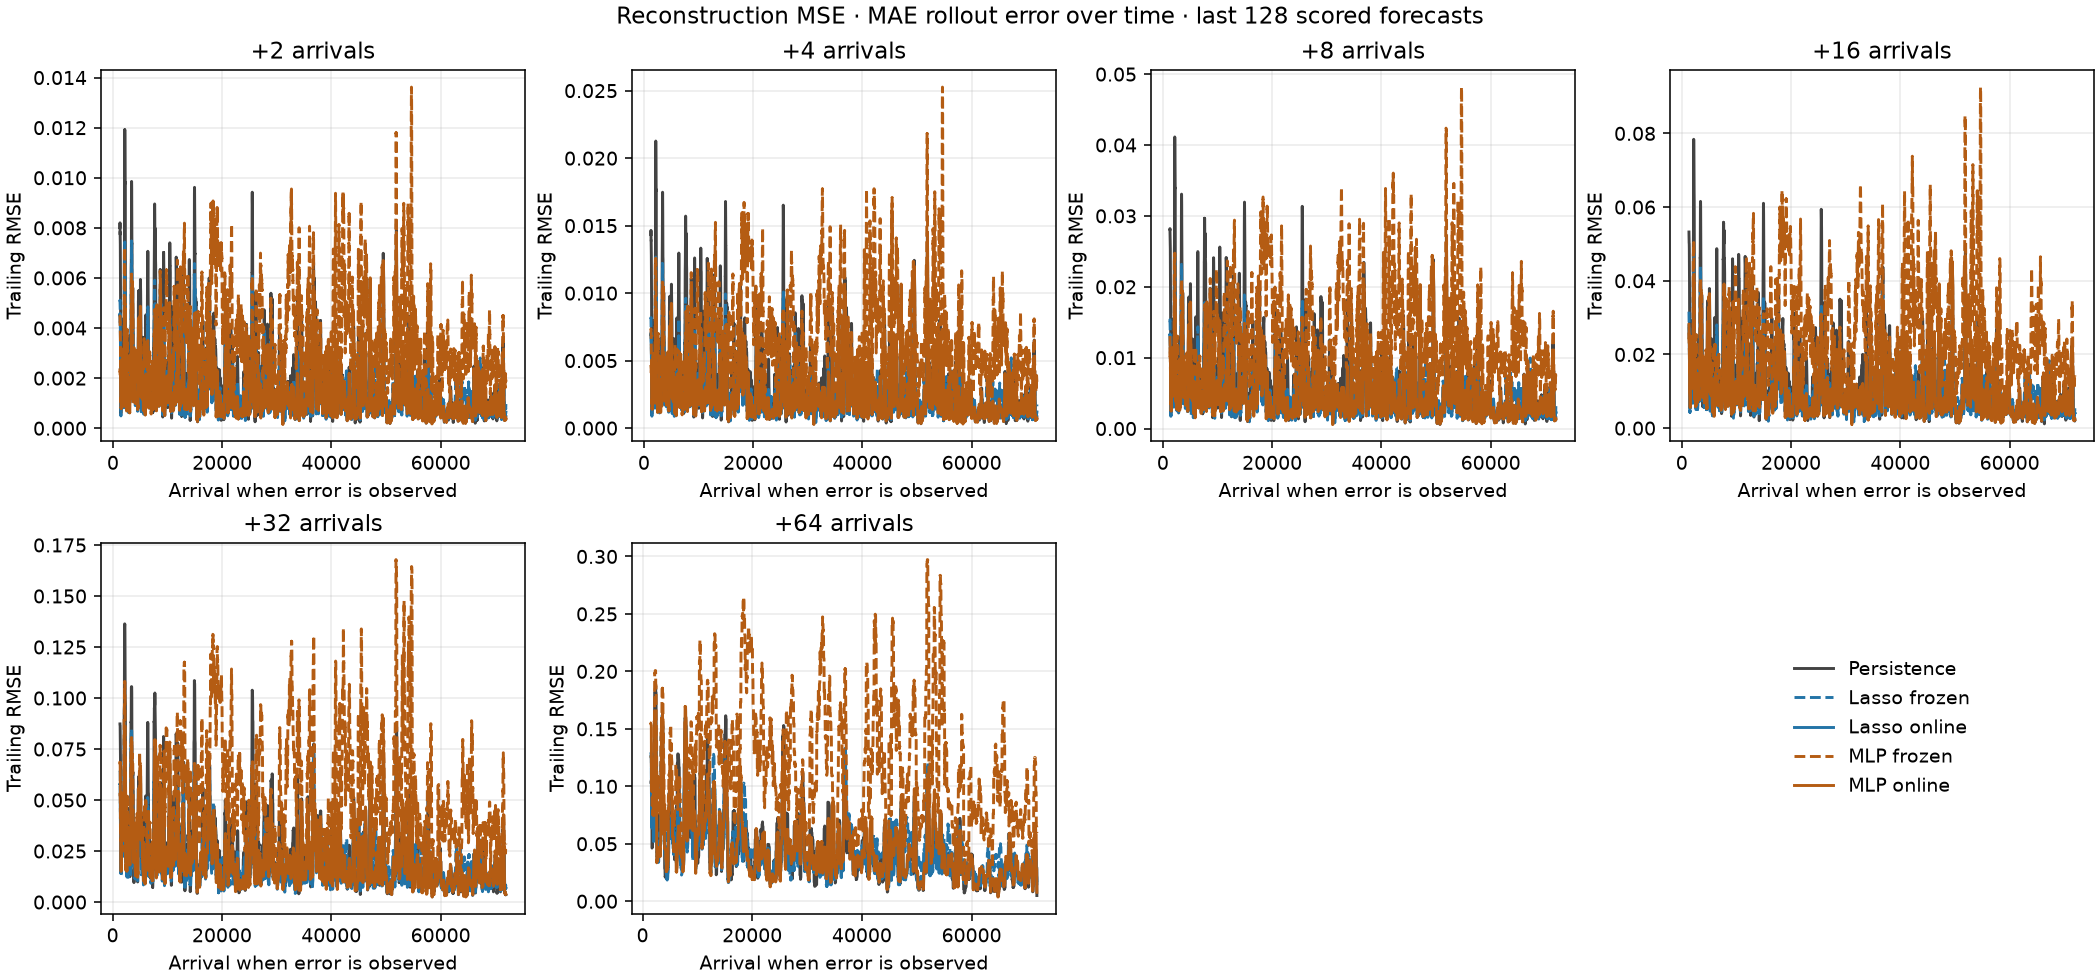

In [ ]:
from IPython.display import Image, display
display(Image(filename='rmse_mse.png'))


## RankMe

| Horizon | Forecasts | Persistence | Lasso frozen | Lasso online | MLP frozen | MLP online |
|---:|---:|---:|---:|---:|---:|---:|
| +2 | 70,046 | 0.00874589 | 0.00798418 | 0.00768392 | 0.0117743 | 0.00753409 |
| +4 | 68,570 | 0.0144502 | 0.0127719 | 0.0124 | 0.020735 | 0.0121678 |
| +8 | 65,618 | 0.025238 | 0.0217538 | 0.0216773 | 0.0388872 | 0.0210809 |
| +16 | 59,714 | 0.0448014 | 0.0382444 | 0.039904 | 0.0753515 | 0.0388109 |
| +32 | 47,906 | 0.077441 | 0.0677703 | 0.0770303 | 0.147928 | 0.0770702 |
| +64 | 24,321 | 0.125103 | 0.117952 | 0.15403 | 0.293422 | 0.153321 |

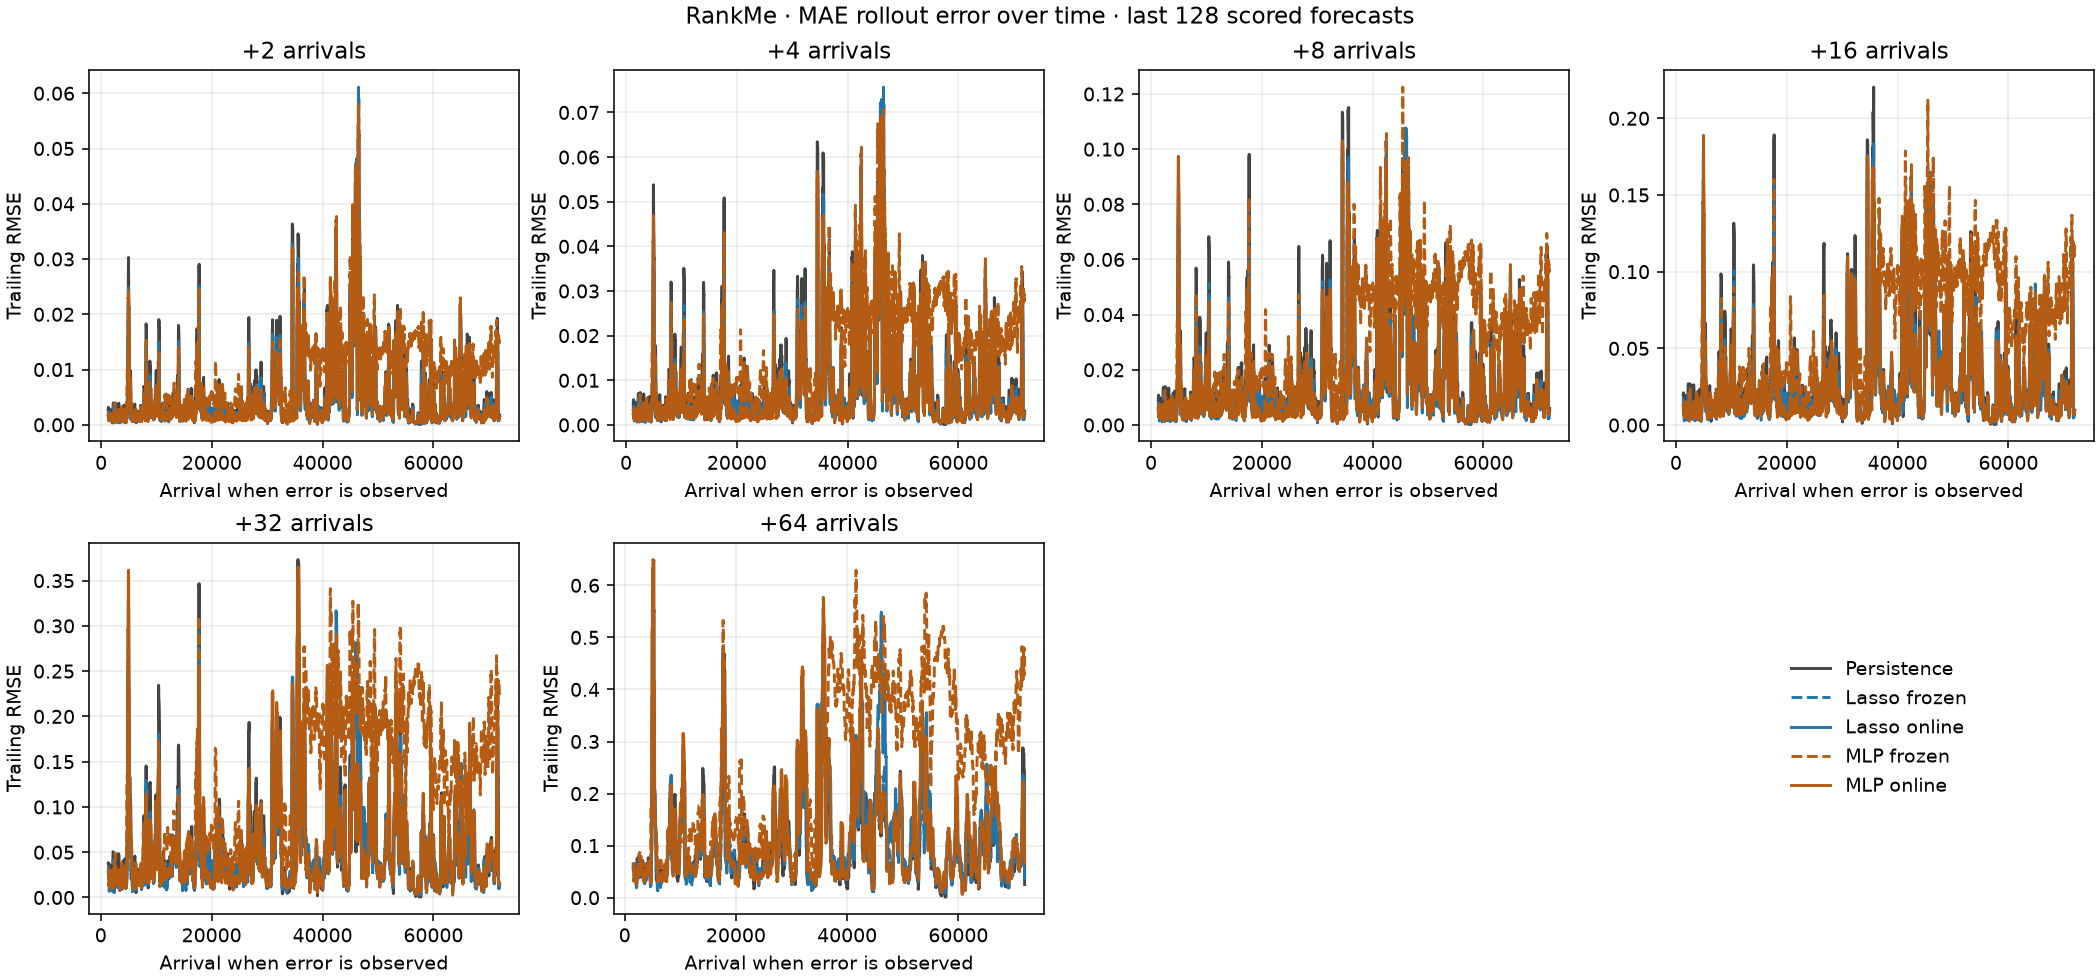

In [ ]:
from IPython.display import Image, display
display(Image(filename='rmse_rankme.png'))


## Feature variance

| Horizon | Forecasts | Persistence | Lasso frozen | Lasso online | MLP frozen | MLP online |
|---:|---:|---:|---:|---:|---:|---:|
| +2 | 70,046 | 0.00187827 | 0.00494226 | 0.00132986 | 0.00277221 | 0.00145347 |
| +4 | 68,570 | 0.00337532 | 0.00928667 | 0.00228098 | 0.00505851 | 0.00261149 |
| +8 | 65,618 | 0.00649141 | 0.0182775 | 0.00445206 | 0.00985296 | 0.00508858 |
| +16 | 59,714 | 0.0125792 | 0.0364083 | 0.00922902 | 0.019586 | 0.0102293 |
| +32 | 47,906 | 0.0234253 | 0.0726485 | 0.0193399 | 0.0393772 | 0.0206152 |
| +64 | 24,321 | 0.0407042 | 0.14532 | 0.040494 | 0.0810241 | 0.0426802 |

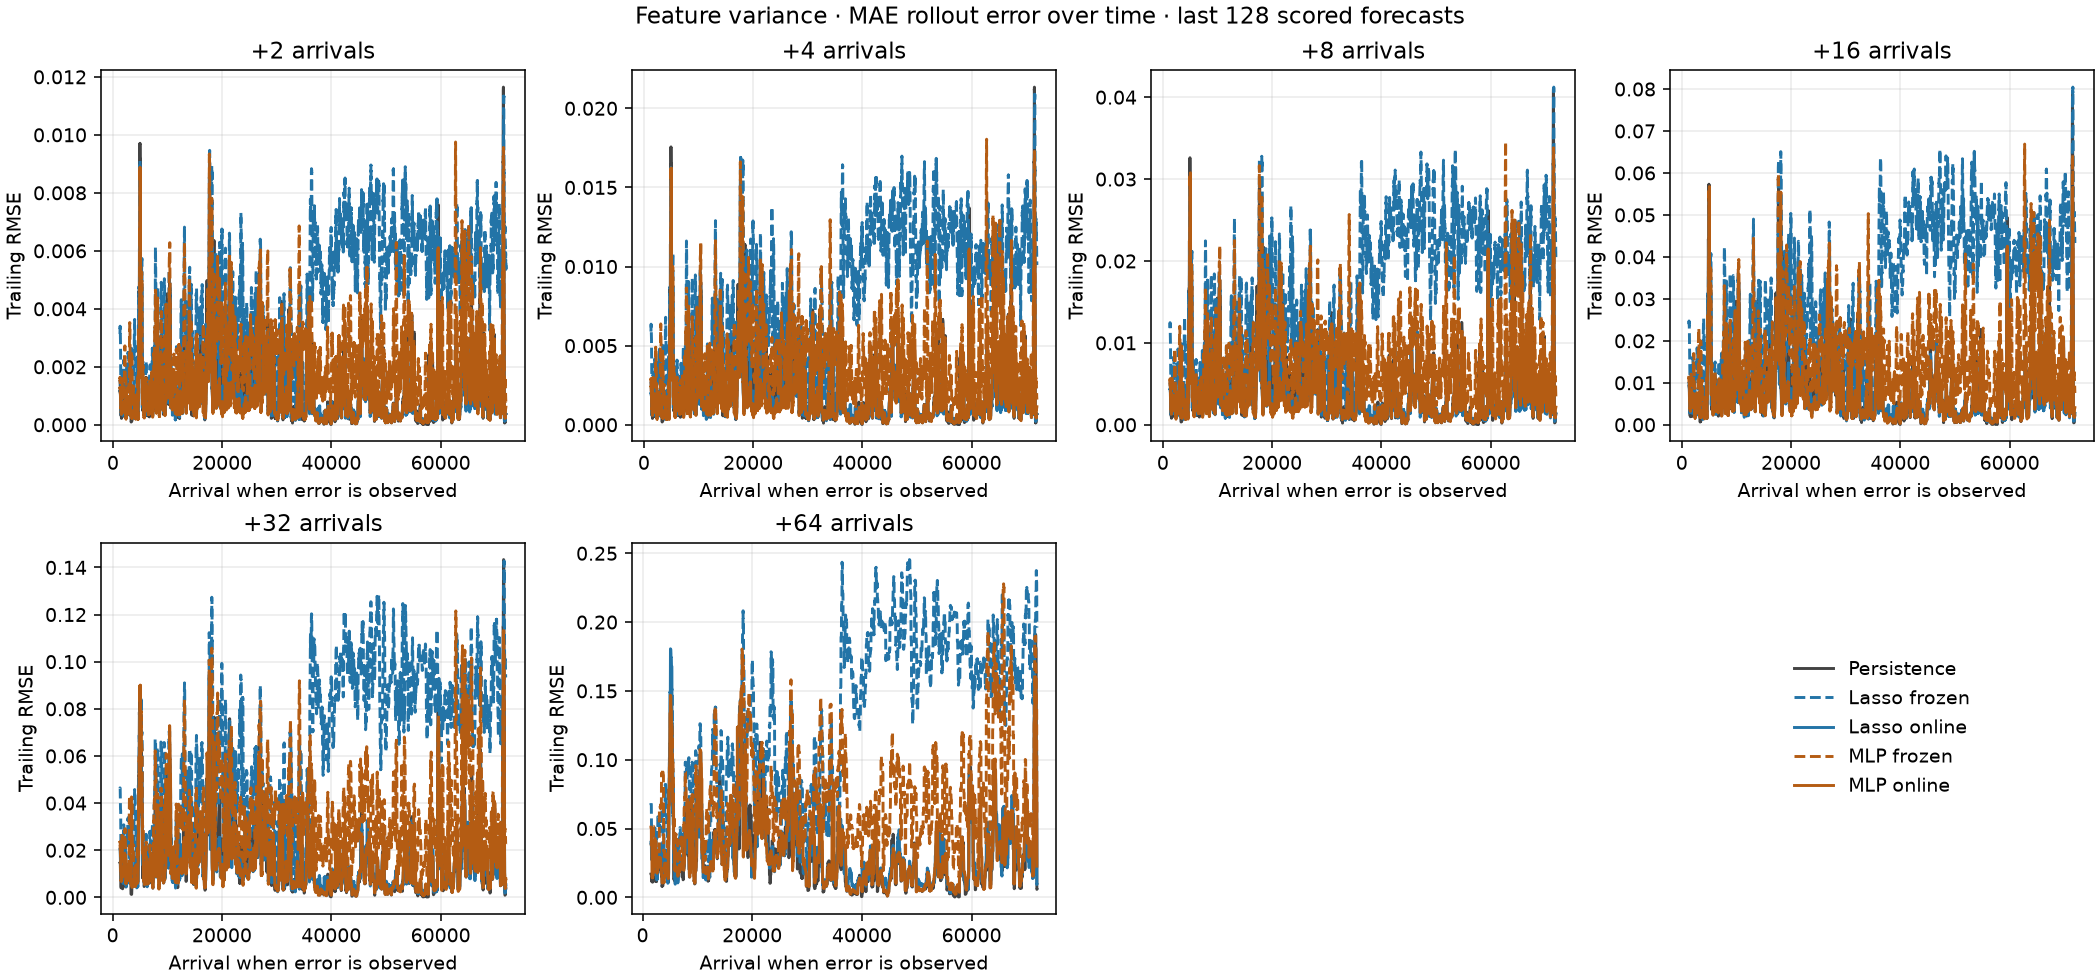

In [ ]:
from IPython.display import Image, display
display(Image(filename='rmse_variance.png'))


## LiDAR

| Horizon | Forecasts | Persistence | Lasso frozen | Lasso online | MLP frozen | MLP online |
|---:|---:|---:|---:|---:|---:|---:|
| +2 | 70,046 | 0.0276069 | 0.0279373 | 0.0278128 | 0.0306131 | 0.0276667 |
| +4 | 68,570 | 0.0425057 | 0.0432372 | 0.0433186 | 0.0491176 | 0.0426677 |
| +8 | 65,618 | 0.0644756 | 0.0661541 | 0.0671984 | 0.080033 | 0.0650309 |
| +16 | 59,714 | 0.0933351 | 0.097853 | 0.100991 | 0.131079 | 0.0950666 |
| +32 | 47,906 | 0.128206 | 0.141338 | 0.148424 | 0.218051 | 0.133148 |
| +64 | 24,321 | 0.169925 | 0.207039 | 0.224793 | 0.372347 | 0.184371 |

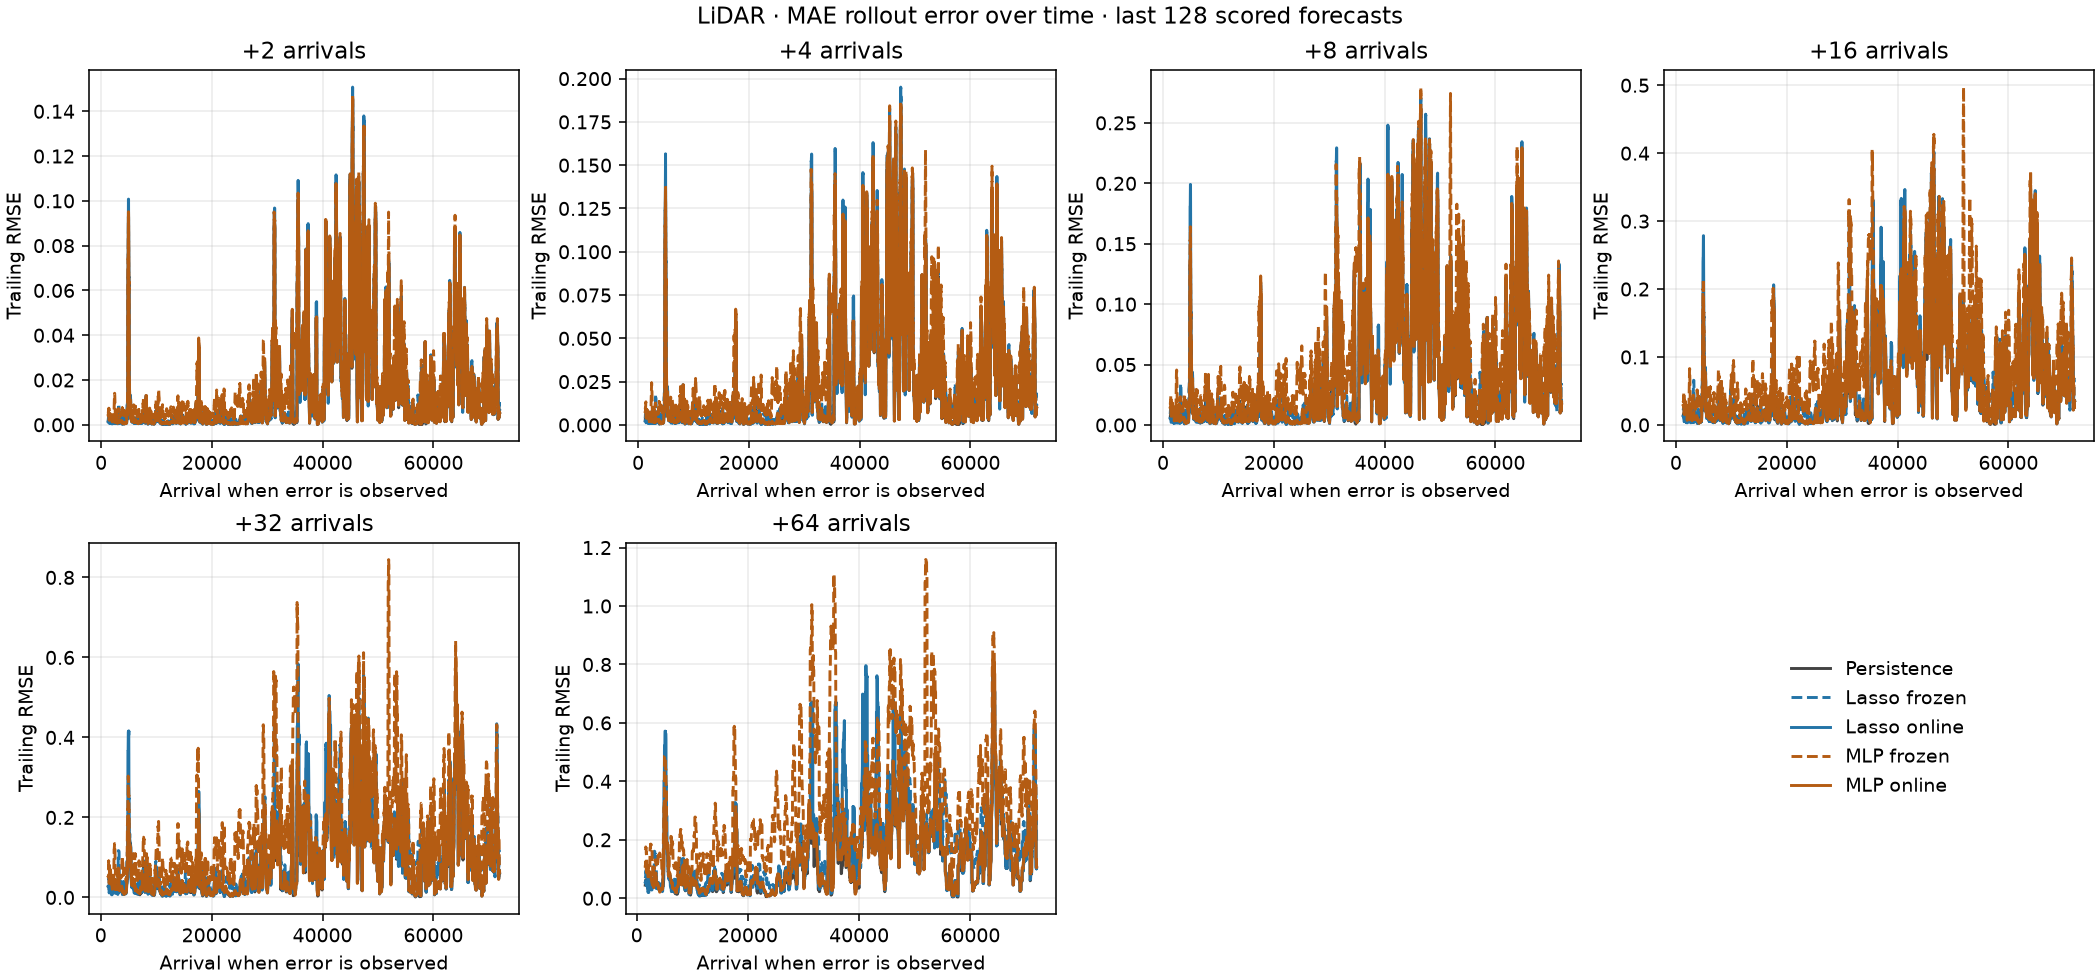

In [ ]:
from IPython.display import Image, display
display(Image(filename='rmse_lidar.png'))


Each rolling RMSE point uses 128 scored forecasts at its horizon.
The horizontal axis is the arrival when the forecast outcome becomes observable.

The leakage audit perturbs future inputs and outcomes after a held-out clip boundary and
checks that every earlier prediction stays identical. The run also checks that online and
frozen predictors issue identical initial forecasts and that clip eligibility matches every
stored forecast. This is a one-seed forecast comparison on a shared action schedule.